From the project root run  
pip install -e .

In [ ]:
from ExTSP.tripletSets_exTSP import get_tripletSets_with_exTSP
import pandas as pd
old_exTSP_file = "src/ExTSP/data/Tulika_data/exTSP_scores/exTSP_score_beta_1_CM.tsv"
exTSP_org = pd.read_csv(old_exTSP_file, sep="\t")
# exTSP_PLP = get_tripletSets_with_exTSP("CM", type="PLP", brainspan=False, by_developmental_period=False, no_P13=False)
# exTSP_BLB = get_tripletSets_with_exTSP("CM", type="BLB", brainspan=False, by_developmental_period=False, no_P13=False)
# exTSP = pd.concat([exTSP_PLP, exTSP_BLB])
exTSP = get_tripletSets_with_exTSP("CM", type="all", brainspan=False, by_developmental_period=False, no_P13=False)



In [ ]:
from matplotlib import pyplot as plt
from ExTSP.config import OLD_DATA_DIR, ExtractedVariants_file
import pandas as pd
print(exTSP_org.head())
print(exTSP.head())
exTSP_org_dedup = exTSP_org.drop_duplicates(subset=["Variant", "Transcript", "Tissue"])
print(len(exTSP_org))
print(len(exTSP))
print(len(exTSP_org_dedup)) 

CM_Varset_file = OLD_DATA_DIR / "targetVariants" / "High_Confident_SNP_mutations_CM.tsv"

CM_Varset_excel = pd.read_excel(ExtractedVariants_file, sheet_name="CM")
CM_Varset_excel_old = pd.read_excel(ExtractedVariants_file, sheet_name="CM_old")
CM_Varset = pd.read_csv(CM_Varset_file, sep="\t")
Varset1 = set(exTSP_org.Variant.unique())
Varset2 = set(exTSP.Variant.unique())
Varset3 = set(CM_Varset.Variant_ID.unique())
Varset4 = set(CM_Varset_excel.Variant.unique())
Varset5 = set(CM_Varset_excel_old.Variant.unique())

missing_var = Varset1-Varset2
missing_var2 = Varset1-Varset3
missing_var3 = Varset1-Varset4
missing_var4 = Varset1-Varset5

print(len(missing_var))
print(len(missing_var2))
print(len(missing_var3))
print(len(missing_var4))




# missing_var = Varset1-Varset2

# exTSP_org_missing = exTSP_org[exTSP_org.Variant.isin(missing_var)]

# plt.hist(exTSP_org_missing.MutPred2)
# plt.show()





      Gene       Transcript      Transcript_id         Variant  \
0  PLEKHM2  ENST00000375793  ENST00000375793.2  1_15727456_A/G   
1  PLEKHM2  ENST00000375793  ENST00000375793.2  1_15727456_A/G   
2  PLEKHM2  ENST00000375793  ENST00000375793.2  1_15727456_A/G   
3  PLEKHM2  ENST00000375793  ENST00000375793.2  1_15727456_A/G   
4  PLEKHM2  ENST00000375793  ENST00000375793.2  1_15727456_A/G   

       ClinVar_annotation                    Tissue  IsoPath  MutPred2  \
0  Uncertain significance      Adipose_Subcutaneous   0.0074    0.3396   
1  Uncertain significance  Adipose_Visceral_Omentum   0.0074    0.3396   
2  Uncertain significance             Adrenal_Gland   0.0074    0.3396   
3  Uncertain significance              Artery_Aorta   0.0074    0.3396   
4  Uncertain significance           Artery_Coronary   0.0074    0.3396   

       ptse     exTSP  MANE_Select  MANE_Plus_Clinical    meanTPM  
0  0.003876  0.000052        False               False   8.479729  
1  0.003766  0.000051 

In [51]:
from ExTSP.config import exTSP_file_gtex
exTSP_df2 = pd.read_csv(exTSP_file_gtex, sep='\t')
print(f"number of rows witout ExTSP scores: {len(exTSP_df[exTSP_df.exTSP.isna()])}")

Vasrset_all = set(exTSP_df2.Variant.unique())

missing_var5 = Varset1-Vasrset_all

print(len(missing_var5))



number of rows witout ExTSP scores: 0
11572


In [46]:
CM_Varset


,GeneSymbol,Variant_ID,Chromosome,Start,Stop,ReferenceAlleleVCF,AlternateAlleleVCF,PhenotypeList,Status
0,RBM20,10_110812310_C/T,10,110812310,110812310,C,T,Dilated cardiomyopathy 1DD|Primary dilated car...,Pathogenic
1,RBM20,10_110812298_G/A,10,110812298,110812298,G,A,Dilated cardiomyopathy 1DD|not provided|Cardio...,Pathogenic/Likely pathogenic
2,RBM20,10_110812303_C/A,10,110812303,110812303,C,A,Dilated cardiomyopathy 1DD|not provided|Primar...,Pathogenic/Likely pathogenic
3,RBM20,10_110812304_G/A,10,110812304,110812304,G,A,Dilated cardiomyopathy 1DD|Primary dilated car...,Pathogenic/Likely pathogenic
4,NEXN,1_77942632_C/A,1,77942632,77942632,C,A,Dilated cardiomyopathy 1CC|Cardiovascular phen...,Uncertain significance
...,...,...,...,...,...,...,...,...,...
27554,FLNC,7_128850905_A/C,7,128850905,128850905,A,C,Hypertrophic cardiomyopathy 26,Uncertain significance
27555,MYH7,14_23427894_G/T,14,23427894,23427894,G,T,Hypertrophic cardiomyopathy 1,Uncertain significance
27556,KIF20A,5_138184309_C/T,5,138184309,138184309,C,T,"Cardiomyopathy, familial restrictive, 6",Likely pathogenic
27557,KIF20A,5_138187156_A/G,5,138187156,138187156,A,G,"Cardiomyopathy, familial restrictive, 6",Uncertain significance


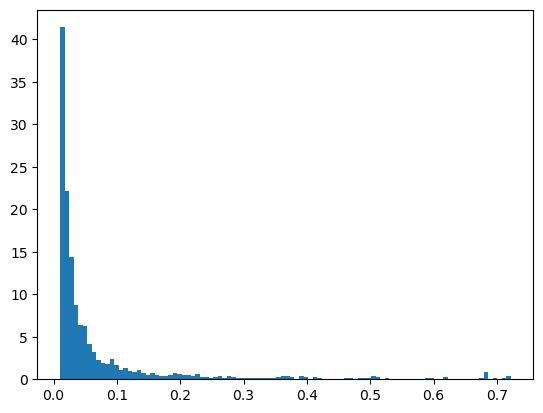

In [26]:
from matplotlib import pyplot as plt
plt.hist(exTSP_df[exTSP_df.exTSP>0.01].exTSP, bins=100, density=True)
plt.show()


length of new: 154114
length of to rescore file: 43682
length of rescored file: 43682
number of variants missing: 0


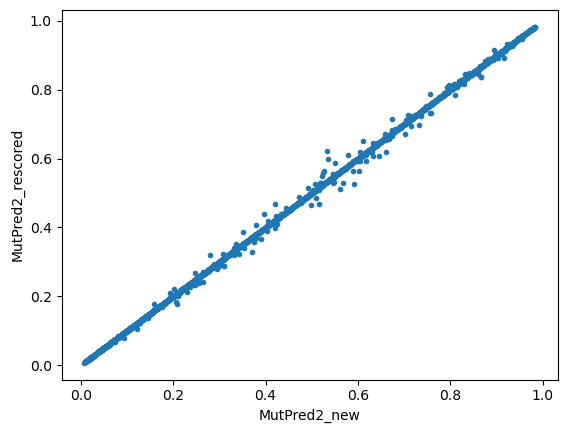

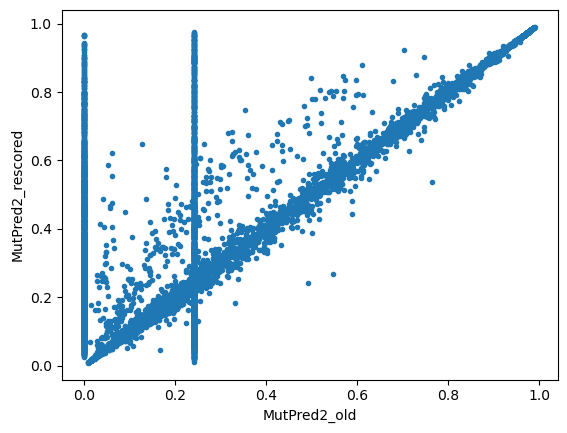

In [ ]:
from re import M
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from ExTSP.config import FILTERED_DIR, MutPred2_filtered_file, ClinVar_master_file, MutPred2_processed_file
from ExTSP.tripletSets_exTSP import get_disease_variants, get_tripletSets_with_exTSP
from pathlib import Path
MP2_DIR = Path("MutPred2_scores")

file_new = MP2_DIR / "MutPred2_for_filtered_variants_SJ.tsv"
file_old = MP2_DIR / "mutpred_score_variant_transcript_Tulika.tsv"
file_new_plus = FILTERED_DIR / "MutPred2_for_filtered_variants_new_plus.tsv"
file_old_plus = FILTERED_DIR / "mutpred_for_filtered_variants_old_plus.tsv"
rescored_file = FILTERED_DIR / "mp2_rescore_combined.tsv"
to_rescore_file =  "mp2_to_rescore2.tsv"

mp2_new = pd.read_csv(file_new, sep="\t")
mp2_new = mp2_new.drop_duplicates(subset=["ID", "Substitution"])
print(f"length of new: {len(mp2_new)}")
mp2_old = pd.read_csv(file_old, sep="\t")
mp2_old.rename(columns={"Feature": "ID", "mutpred": "MutPred2_old", "mutation": "Variant"}, inplace=True)
mp2_old = mp2_old[["Variant", "ID", "Substitution",	"MutPred2_old"]]
mp2_old = mp2_old.drop_duplicates(subset=["Variant", "ID", "Substitution"])

mp2_to_rescore = pd.read_csv(to_rescore_file, sep="\t") 
print(f"length of to rescore file: {len(mp2_to_rescore)}")
mp2_rescored = pd.read_csv(rescored_file, sep="\t")
print(f"length of rescored file: {len(mp2_rescored)}")

variants_to_rescore = mp2_to_rescore.Variant.unique()
variants_rescored = mp2_rescored.Variant.unique()
variants_missing = np.setdiff1d(variants_to_rescore, variants_rescored)
print(f"number of variants missing: {len(variants_missing)}")

overlap_with_new = mp2_new.merge(mp2_rescored, on=["ID", "Substitution"], how="inner")

plt.plot(overlap_with_new.MutPred2_x, overlap_with_new.MutPred2_rescored, ".")
plt.xlabel("MutPred2_new")
plt.ylabel("MutPred2_rescored")
plt.show()

overlap_with_old = mp2_old.merge(mp2_rescored, on=["Variant", "ID", "Substitution"], how="inner")

plt.plot(overlap_with_old.MutPred2_old, overlap_with_old.MutPred2_rescored, ".")
plt.xlabel("MutPred2_old")
plt.ylabel("MutPred2_rescored")
plt.show()












In [19]:
#mp2_to_rescore = pd.read_csv("mp2_to_rescore2.csv", sep="\t")

from operator import le
import pandas as pd
from ExTSP.config import VariantAnnotations_file
file_new = "./MutPred2_scores/MutPred2_for_filtered_variants_new.tsv"
file_new_plus = "./MutPred2_scores/MutPred2_for_filtered_variants_new_plus.tsv"
rescored_file = "./MutPred2_scores/mp2_rescore_combined.tsv"

# print(len(mp2_to_rescore))
# print(mp2_to_rescore.columns)
# print(mp2_rescored.columns)
# len(mp2_rescored)
mp2_new = pd.read_csv(file_new, sep="\t")
print(f"length of mp2_new: {len(mp2_new)}")
print(f"length of mp2_new_dedup: {len(mp2_new.drop_duplicates(subset=['ID', 'Substitution']))}")

mp2_new_plus = pd.read_csv(file_new_plus, sep="\t")
print(mp2_new_plus.columns)
print(f"length of mp2_new_plus: {len(mp2_new_plus)}")
print(len(mp2_new_plus.drop_duplicates(subset=["ID", "Substitution"])))

mp2_rescored = pd.read_csv(rescored_file, sep="\t")

mp2_new_rescored = mp2_new.merge(mp2_rescored[["Substitution", "ID", "Variant", "MutPred2_rescored"]], on=["ID", "Substitution"], how="outer")

print(mp2_new_rescored.columns)
# for _, dup in mp2_new_rescored.groupby(["ID", "Substitution"]):
#     if len(dup) > 1:
#         if dup.MutPred2_rescored.var() > 0.0001:
#             print(dup)

# mp2_new_rescored.drop_duplicates(subset=["ID", "Substitution"], inplace=True)  
# print(f"length of mp2_new_rescored: {len(mp2_new_rescored)}")


print(mp2_new_rescored["MutPred2"].isna().sum())
mp2_new_rescored.loc[mp2_new_rescored.MutPred2.isna(), "MutPred2"] = mp2_new_rescored.loc[mp2_new_rescored.MutPred2.isna(), "MutPred2_rescored"]
print(mp2_new_rescored["MutPred2"].isna().sum())
mp2_new_rescored.drop(columns=["MutPred2_rescored"], inplace=True)
#mp2_new_rescored.dropna(inplace=True)
#print(mp2_new_rescored.MutPred2.isna().sum())

#print(mp2_to_rescore["MutPred2"].isna().sum())

print(len(mp2_new_rescored))

Variant_annotation = pd.read_csv(VariantAnnotations_file, sep="\t")
Variant_annotation = Variant_annotation[["ENST", "aa_sub", "Variant"]].drop_duplicates(subset=["ENST", "aa_sub", "Variant"])
Variant_annotation.rename(columns={"ENST": "ID", "aa_sub": "Substitution"}, inplace=True)
Variant_annotation2 = mp2_new_rescored[["ID", "Substitution", "Variant"]].drop_duplicates(subset=["ID", "Substitution", "Variant"])
#Variant_annotation2.rename(columns={"ID": "ENST", "Substitution": "aa_sub", "Variant": "Variant2"}, inplace=True)
Variant_annotation2.rename(columns={"Variant": "Variant2"}, inplace=True)
Variant_annotation3 = Variant_annotation.merge(Variant_annotation2, on=["ID", "Substitution"], how="outer")
Variant_annotation3.loc[Variant_annotation3.Variant.isna(), "Variant"] = Variant_annotation3.loc[Variant_annotation3.Variant.isna(), "Variant2"]
print(f"Enpyt variant field count: {Variant_annotation3.Variant.isna().sum()}")
print(f"Empty Variant2 field count: {Variant_annotation3.Variant2.isna().sum()}")
ct = 0  
additional_rows = []
for _, row in Variant_annotation3.iterrows():
    if (row["Variant2"] != row["Variant"]) and not(pd.isna(row["Variant2"]) or pd.isna(row["Variant"])):
        #print(row)
        row["Variant"] = row["Variant2"]
        additional_rows.append(row)
        ct += 1 
print(ct)
additional_rows = pd.DataFrame(additional_rows)
print(f"length of additional_rows: {len(additional_rows)}")
print(f"length of variant_annotation3: {len(Variant_annotation3)}")
Variant_annotation3 = pd.concat([Variant_annotation3, additional_rows])
Variant_annotation3.drop(columns=["Variant2"], inplace=True)
print(f"length of variant_annotation3: {len(Variant_annotation3)}")
Variant_annotation3.drop_duplicates(subset=["Variant", "ID", "Substitution"], inplace=True)
print(f"length of variant_annotation3: {len(Variant_annotation3)}")
#assert Variant_annotation3[Variant_annotation3["Variant_x"] != Variant_annotation3["Variant_y"]].isna().all()
#Variant_annotation3.dropna(inplace=True)
Variant_annotation3.drop_duplicates(subset=["Variant", "ID", "Substitution"], inplace=True)
mp2_new_rescored.drop(columns=["Variant"], inplace=True)
print(f"length of mp2_new_rescored: {len(mp2_new_rescored)}")
mp2_new_rescored.drop_duplicates(subset=["ID", "Substitution"], inplace=True)
print(f"length of mp2_new_rescored: {len(mp2_new_rescored)}")
mp2_new_rescored = mp2_new_rescored.merge(Variant_annotation3, on=["ID", "Substitution"], how="left")
print(f"length of mp2_new_rescored: {len(mp2_new_rescored)}")
mp2_new_rescored.drop_duplicates(subset=["Variant", "ID", "Substitution"], inplace=True)
print(f"length of mp2_new_rescored: {len(mp2_new_rescored)}")

mp2_new_rescored = mp2_new_rescored[["Variant", "ID", "Substitution", "MutPred2"]]
mp2_new_rescored.rename(columns={"ID": "ENST", "Substitution": "aa_sub"}, inplace=True)

mp2_new_rescored.to_csv("mp2_new_rescored.tsv", sep="\t", index=False)






length of mp2_new: 154114
length of mp2_new_dedup: 154114
Index(['Variant', 'ID', 'Substitution', 'MutPred2'], dtype='object')
length of mp2_new_plus: 193706
193407
Index(['ID', 'Substitution', 'MutPred2', 'Variant', 'MutPred2_rescored'], dtype='object')
39474
8
193613


/var/folders/lj/6gfrhbf15_1_dhvth8xrbgjr0000gn/T/ipykernel_34520/1566840756.py:48: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  Variant_annotation = pd.read_csv(VariantAnnotations_file, sep="\t")


Enpyt variant field count: 0
Empty Variant2 field count: 150641
53
length of additional_rows: 53
length of variant_annotation3: 194376
length of variant_annotation3: 194429
length of variant_annotation3: 194326
length of mp2_new_rescored: 193613
length of mp2_new_rescored: 193407
length of mp2_new_rescored: 194275
length of mp2_new_rescored: 194275


In [10]:
mp2_new_rescored.Variant.isna().sum()

np.int64(0)

In [ ]:
from ExTSP.tripletSets_exTSP import get_variant_sets, get_tripletSets_with_exTSP_old2
import re
df_MDV = get_tripletSets_with_exTSP_old2("PKD", type="PLP", SDV=False)
df_SDV = get_tripletSets_with_exTSP_old2("PKD", type="PLP", SDV=True)
var_mdv = set(  df_MDV.Variant.to_list())
var_sdv = set(df_SDV.Variant.to_list())
var_diff = var_mdv - var_sdv
df_diff = df_MDV[df_MDV.Variant.isin(var_diff)]
df_diff = df_diff[["Variant"]].drop_duplicates()
df_varset = get_variant_sets("PKD", type="PLP", SDV=False)
df_diff = df_diff.merge(df_varset, left_on="Variant", right_on="Variant_ID", how="left")
print(df_diff.columns)
print(df_diff.shape)
Pheno_terms = [p for ph in df_diff.PhenotypeList.to_list() for p in re.split(r'[|,;]', ph)]

[print(ph) for ph in df_diff.PhenotypeList.to_list()]
df_diff.GeneSymbol.nunique()


In [3]:
from ExTSP.tripletSets_exTSP import get_variant_sets, get_tripletSets_with_exTSP
df = get_tripletSets_with_exTSP("ASD", type="all", brainspan=True, by_developmental_period=True, no_P13=True)
df.to_csv("ASD_brainspan_by_period_no_P13.tsv", sep="\t", index=False)
# df = get_tripletSets_with_exTSP("ASD", type="all", brainspan=True, by_developmental_period=False, no_P13=True)
# df.to_csv("ASD_brainspan_cortical_by_region_no_P13.tsv", sep="\t", index=False)
print(df.Developmental_Period.unique())

df.Region.unique()

['P2' 'P3' 'P4' 'P5' 'P6' 'P7' 'P8' 'P9' 'P10' 'P11' 'P12']


array(['Amygdala', 'Cerebellum', 'Cortex', 'Hippocampus', 'Striatum ',
       'Thalamus'], dtype=object)

In [2]:
from ExTSP.config import OLD_DATA_DIR
import pandas as pd
old_file = OLD_DATA_DIR / "exTSP_scores/exTSP_score_beta_1_Cortical_Chau11.tsv"
old_df = pd.read_csv(old_file, sep="\t")
old_df = old_df[old_df.ClinVar_annotation.isin(["ASD"])]
print(old_df.columns)
print(df.columns)
old_df.rename(columns={"Tissue": "Developmental_Period"}, inplace=True)
#old_df = old_df[["Variant", "Transcript", "Developmental_Period", "meanTPM", "ptse","exTSP", "IsoPath"]]
#df = df[["Variant", "Transcript", "Developmental_Period", "meanTPM", "ptse","exTSP", "IsoPath"]]
old_df = old_df.merge(df, on=["Variant", "Transcript", "Developmental_Period"], how="inner")




Index(['Gene', 'Transcript', 'Transcript_id', 'Variant', 'ClinVar_annotation',
       'Tissue', 'IsoPath', 'MutPred2', 'ptse', 'exTSP', 'MANE_Select',
       'MANE_Plus_Clinical', 'meanTPM'],
      dtype='object')
Index(['Gene', 'Transcript', 'Transcript_id', 'Variant', 'MutPred2', 'IsoPath',
       'ptse', 'exTSP', 'meanTPM', 'Developmental_Period', 'Region',
       'MANE_Select', 'MANE_Plus_Clinical', 'Status', 'ClinVar_annotation',
       'In_ClinVar'],
      dtype='object')


In [3]:
import numpy as np
from ExTSP.exTSP_compute.compute_PTSE import PTSE
#old_file = DATA_DIR / "processed/exTSP_brainspan_cortical.tsv"
#old_df = pd.read_csv(old_file, sep="\t")
# print(old_df.head())
# print(old_df.columns)
# print(df.columns)
# old_df = old_df[["Variant", "Transcript", "Developmental_Period", "meanTPM", "ptse","exTSP", "IsoPath"]]

#print((old_df.ptse_x - old_df.ptse_y).abs().argsort()[-20:])
# print((old_df.exTSP_x - old_df.exTSP_y).abs().argsort()[-20:])
# print((old_df.IsoPath_x - old_df.IsoPath_y).abs().argsort()[-20:])
old_df1 = old_df.drop_duplicates(subset=["Variant", "Transcript", "Developmental_Period"])
old_df_wide = old_df1.pivot(index=["Variant", "Transcript"], columns="Developmental_Period", values="meanTPM_x")
df_wide = old_df1.pivot(index=["Variant", "Transcript"], columns="Developmental_Period", values="meanTPM_y")

#non_zeros = old_df_wide.sum(axis=1) > 0

tpms = old_df_wide.iloc[0]
variant, transcript = old_df_wide.index[0]

mean = tpms.mean()
std = tpms.std()
z_score = (tpms - mean) / std
z_score_max = z_score.max()
exp1 = z_score.apply(lambda x: np.exp(x-z_score_max))
exp = z_score.apply(lambda x: np.exp(x))

exTSP = exp/exp.sum()
exTSP1 = exp1/exp1.sum()

tpms_np = tpms.to_numpy().reshape((1,12))
ptse = PTSE(tpms_np)






df2 = old_df[old_df.ptse_x - old_df.ptse_y == 0]

(old_df.exTSP_x - old_df.exTSP_y).abs().max()
(old_df.IsoPath_x - old_df.IsoPath_y).abs().max()
idx = (old_df.ptse_x - old_df.ptse_y).abs().argsort()[-20:]

print(df2.head())
print((old_df.ptse_x - old_df.ptse_y).abs().min())
print((old_df.meanTPM_x - old_df.meanTPM_y).abs().max())

for i in idx:
    print(old_df.loc[i])



Empty DataFrame
Columns: [Gene_x, Transcript, Transcript_id_x, Variant, ClinVar_annotation_x, Developmental_Period, IsoPath_x, MutPred2_x, ptse_x, exTSP_x, MANE_Select_x, MANE_Plus_Clinical_x, meanTPM_x, Gene_y, Transcript_id_y, MutPred2_y, IsoPath_y, ptse_y, exTSP_y, meanTPM_y, Region, MANE_Select_y, MANE_Plus_Clinical_y, Status, ClinVar_annotation_y, In_ClinVar]
Index: []

[0 rows x 26 columns]
1.9727567804883606e-06
1.1368683772161603e-13
Gene_x                             KCNMA1
Transcript                ENST00000372440
Transcript_id_x         ENST00000372440.6
Variant                   10_77403888_C/T
ClinVar_annotation_x                  ASD
Developmental_Period                  P13
IsoPath_x                          0.0171
MutPred2_x                          0.451
ptse_x                           0.083333
exTSP_x                            0.0171
MANE_Select_x                       False
MANE_Plus_Clinical_x                False
meanTPM_x                             0.0
Gene_y  

In [92]:
print(old_df[(old_df.Variant == "10_76910027_G/A") & (old_df.Transcript == "ENST00000372440")])
print(df[(df.Variant == "10_76910027_G/A") & (df.Transcript == "ENST00000372440")])


      Gene_x       Transcript    Transcript_id_x          Variant  \
2856  KCNMA1  ENST00000372440  ENST00000372440.6  10_76910027_G/A   
2857  KCNMA1  ENST00000372440  ENST00000372440.6  10_76910027_G/A   
2858  KCNMA1  ENST00000372440  ENST00000372440.6  10_76910027_G/A   
2859  KCNMA1  ENST00000372440  ENST00000372440.6  10_76910027_G/A   
2860  KCNMA1  ENST00000372440  ENST00000372440.6  10_76910027_G/A   
2861  KCNMA1  ENST00000372440  ENST00000372440.6  10_76910027_G/A   
2862  KCNMA1  ENST00000372440  ENST00000372440.6  10_76910027_G/A   
2863  KCNMA1  ENST00000372440  ENST00000372440.6  10_76910027_G/A   
2864  KCNMA1  ENST00000372440  ENST00000372440.6  10_76910027_G/A   
2865  KCNMA1  ENST00000372440  ENST00000372440.6  10_76910027_G/A   
2866  KCNMA1  ENST00000372440  ENST00000372440.6  10_76910027_G/A   
2867  KCNMA1  ENST00000372440  ENST00000372440.6  10_76910027_G/A   
5928  KCNMA1  ENST00000372440  ENST00000372440.6  10_76910027_G/A   
5929  KCNMA1  ENST00000372440  ENS

length of new: 154114
length of old: 632653
length of CM: 25418
number of unique variants: 25418
length of PCD: 6946
number of unique variants: 6946
length of PH: 342
number of unique variants: 342
length of PKD: 1724
number of unique variants: 1724
length of ASD: 1436
number of unique variants: 1425
length of old only target: 111198
length of new plus: 241637
length of new plus: 241637
length of old plus: 241637
length of common: 23820
length of common missmatch: 3210
length of variant-transcripts missing in new: 87378
Number of variants missing in new: 34746
length of common + missing: 111198
number of variants transcripts not in new: 87378
number of variants not in new: 34746
number of variants transcripts not in old: 130439
number of variants transcripts not in new: 0
number of variants transcripts not in old: 0
154114
111198
23820
20401


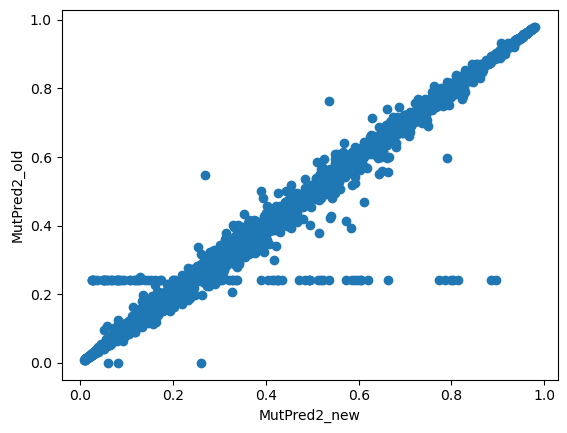

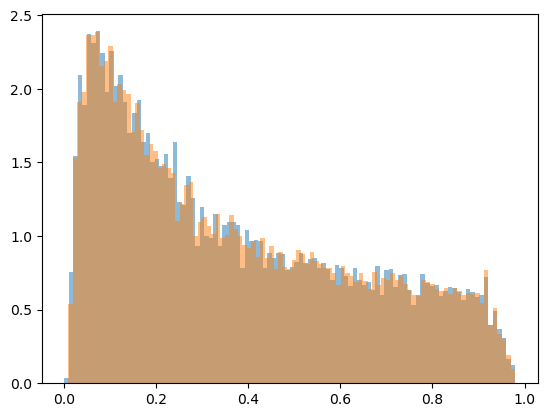

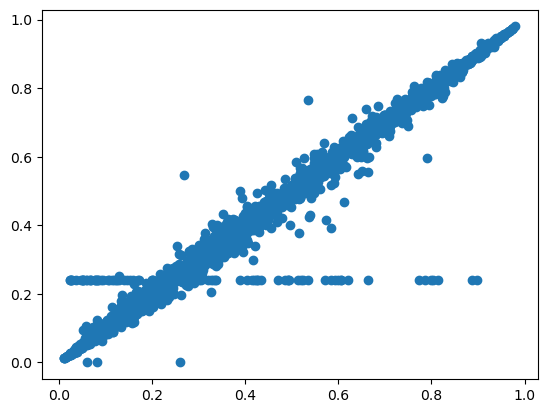

In [57]:
import pandas as pd
from matplotlib import pyplot as plt
from ExTSP.config import FILTERED_DIR, MutPred2_filtered_file, ClinVar_master_file, MutPred2_processed_file
from ExTSP.tripletSets_exTSP import get_disease_variants, get_tripletSets_with_exTSP
from pathlib import Path
MP2_DIR = Path("MutPred2_scores")
file_new = MP2_DIR / "MutPred2_for_filtered_variants_SJ.tsv"
file_old = MP2_DIR / "mutpred_score_variant_transcript_tulika.tsv"
file_new_plus = MP2_DIR / "MutPred2_for_filtered_variants_new_plus.tsv"
file_old_plus = MP2_DIR / "mutpred_for_filtered_variants_old_plus.tsv"


mp2_new = pd.read_csv(file_new, sep="\t")
mp2_new = mp2_new.drop_duplicates(subset=["ID", "Substitution"])
print(f"length of new: {len(mp2_new)}")
mp2_old = pd.read_csv(file_old, sep="\t")
print(f"length of old: {len(mp2_old)}")
mp2_old.rename(columns={"Feature": "ID", "mutpred": "MutPred2_old", "mutation": "Variant"}, inplace=True)
mp2_old = mp2_old[["Variant", "ID", "Substitution",	"MutPred2_old"]]
mp2_old = mp2_old.drop_duplicates(subset=["Variant", "ID", "Substitution"])
diseases = ["CM", "PCD", "PH", "PKD", "ASD"]
df_vars = pd.DataFrame()
for disease in diseases:
    df_disease = get_disease_variants(disease)
    #print(df_disease.columns)
    print(f"length of {disease}: {len(df_disease)}")
    df_disease_dedup = df_disease.drop_duplicates(subset=["Variant", "GeneSymbol"])
    print(f"number of unique variants: {len(df_disease_dedup)}")
    df_vars = pd.concat([df_vars, df_disease])   
old_disease_variants = df_vars["Variant"].unique()
non_target_vars = get_disease_variants("nonTarget")["Variant"].unique()
mp2_new_processed = pd.read_csv(MutPred2_processed_file, sep="\t")
mp2_old = mp2_old[mp2_old.Variant.isin(old_disease_variants)]
mp2_new_non_target = mp2_new_processed[mp2_new_processed.Variant.isin(non_target_vars)]
print(f"length of old only target: {len(mp2_old)}")
mp2_new_plus = mp2_new.merge(mp2_old, on=["ID", "Substitution"], how="outer")
print(f"length of new plus: {len(mp2_new_plus)}")
mp2_new_plus = mp2_new_plus[["Variant", "ID", "Substitution", "MutPred2", "MutPred2_old"]]
print(f"length of new plus: {len(mp2_new_plus)}")
mp2_old_plus = mp2_old.merge(mp2_new, on=["ID", "Substitution"], how="outer")
print(f"length of old plus: {len(mp2_old_plus)}")
mp2_common = mp2_new.merge(mp2_old, on=["ID", "Substitution"], how="inner")
print(f"length of common: {len(mp2_common)}")
mp2_common_missmatch = mp2_common[(mp2_common.MutPred2 - mp2_common.MutPred2_old).abs()>0.0001].copy()
print(f"length of common missmatch: {len(mp2_common_missmatch)}")
idx_new_plus_na = mp2_new_plus[mp2_new_plus.MutPred2.isna()].index
mp2_missing = mp2_new_plus.loc[idx_new_plus_na].copy()
print(f"length of variant-transcripts missing in new: {len(mp2_missing)}")
print(f"Number of variants missing in new: {mp2_missing.Variant.nunique()}")
print(f"length of common + missing: {len(mp2_common)+len(mp2_missing)}")
print(f"number of variants transcripts not in new: {len(idx_new_plus_na)}")
print(f"number of variants not in new: {len(mp2_new_plus.loc[idx_new_plus_na].Variant.unique())}")
idx_old_plus_na = mp2_old_plus[mp2_old_plus.MutPred2_old.isna()].index
print(f"number of variants transcripts not in old: {len(idx_old_plus_na)}")
mp2_new_plus.loc[idx_new_plus_na, "MutPred2"] = mp2_new_plus.loc[idx_new_plus_na, "MutPred2_old"]
mp2_old_plus.loc[idx_old_plus_na, "MutPred2_old"] = mp2_old_plus.loc[idx_old_plus_na, "MutPred2"]
mp2_new_plus.drop(columns=["MutPred2_old"], inplace=True)
mp2_old_plus.drop(columns=["MutPred2"], inplace=True)
mp2_old_plus.rename(columns={"MutPred2_old": "MutPred2"}, inplace=True)
mp2_new_plus.to_csv(file_new_plus, sep="\t", index=False)
mp2_old_plus.to_csv(file_old_plus, sep="\t", index=False)
idx_new_plus_na = mp2_new_plus[mp2_new_plus.MutPred2.isna()].index
print(f"number of variants transcripts not in new: {len(idx_new_plus_na)}")
idx_old_plus_na = mp2_old_plus[mp2_old_plus.MutPred2.isna()].index
print(f"number of variants transcripts not in old: {len(idx_old_plus_na)}")
print(len(mp2_new))
print(len(mp2_old))
print(len(mp2_common))
print((mp2_common.MutPred2 - mp2_common.MutPred2_old == 0.0).sum())
plt.xlabel("MutPred2_new")
plt.ylabel("MutPred2_old")
plt.scatter(mp2_common.MutPred2, mp2_common.MutPred2_old)
plt.show()

plt.hist(mp2_common.MutPred2_old, bins=100, density=True, alpha=0.5)
plt.hist(mp2_common.MutPred2, bins=100, density=True, alpha=0.5)
plt.show()
plt.scatter(mp2_common_missmatch.MutPred2, mp2_common_missmatch.MutPred2_old)
plt.show()










In [48]:
"""Data generated from this code on 27-07-2026"""
from ExTSP.config import PROCESSED_DIR
from pathlib import Path
import pandas as pd
from ExTSP.exTSP_compute.helper import filter_by_transcripts, map_to_genomic_variants
from ExTSP.tripletSets_exTSP import get_disease_variants
from pathlib import Path

diseases = ["CM", "PCD", "PH", "PKD", "ASD"]
MP2_DIR = Path("MutPred2_scores")
file_new = MP2_DIR / "MutPred2_for_filtered_variants_SJ.tsv"
file_old = MP2_DIR / "mutpred_score_variant_transcript_tulika.tsv"
mp2_processed_file = PROCESSED_DIR / 'MP2_Iso_obsolete' / "MutPred2_processed_with_IsoPath_new.tsv"
mp2_new = pd.read_csv(file_new, sep="\t")
mp2_new = map_to_genomic_variants(mp2_new)
mp2_new.rename(columns={"Variant": "Variant_new"}, inplace=True)
print(f"length of mp2_new: {len(mp2_new)}")
# mp2_new_processed = pd.read_csv(mp2_processed_file, sep="\t")
# print(f"length of mp2_new_processed: {len(mp2_new_processed)}")
mp2_old = pd.read_csv(file_old, sep="\t")
mp2_old.rename(columns={"mutation": "Variant", "Feature": "ID"}, inplace=True)
df_vars = pd.DataFrame()
for disease in diseases:
    df_disease = get_disease_variants(disease)
    #print(df_disease.columns)
    print(f"length of {disease}: {len(df_disease)}")
    df_disease_dedup = df_disease.drop_duplicates(subset=["Variant", "GeneSymbol"])
    print(f"number of unique variants: {len(df_disease_dedup)}")
    df_vars = pd.concat([df_vars, df_disease])   
old_disease_variants = df_vars["Variant"].unique()
mp2_old = mp2_old[mp2_old.Variant.isin(old_disease_variants)]
exTSP_file_gtex_new = PROCESSED_DIR / "exTSP_obsolete" / "exTSP_gtex_new.tsv"
ptse_file = PROCESSED_DIR / "GTEx_PTSE.tsv"
exTSP_new = pd.read_csv(exTSP_file_gtex_new, sep='\t')
df_ptse = pd.read_csv(ptse_file, sep='\t')
mp2_new['transcript'] = mp2_new['ID'].str.split('.').str[0]
mp2_old['transcript'] = mp2_old['ID'].str.split('.').str[0]
print(len(mp2_old))
#mp2_old = filter_by_transcripts(mp2_old, df_ptse.transcript_id.unique(), transcript_column="ID")
#print(len(mp2_old))
mp2_old_left = mp2_old.merge(mp2_new, left_on=["transcript", "Variant"], right_on=["transcript", "Variant_new"], how="left")
vars_new = set(mp2_new.Variant_new.unique())
vars_old = set(mp2_old.Variant.unique())
missing = mp2_old_left[mp2_old_left.MutPred2.isna()]

missing_vars1 = vars_old-vars_new
missing_vars2 = missing.Variant.unique()


print(f"length of missing vars: {len(missing_vars1)}")
print(f"Unique variants in  missing: {len(missing_vars2)}")
delta_var =set(missing_vars2)-set(missing_vars1)
delta_var_list = list(delta_var)
print(len(delta_var_list))


mp2_old[mp2_old.Variant == missing.Variant.unique()[0]].ID.unique()











/Users/shajain/Library/CloudStorage/OneDrive-NortheasternUniversity/Box Sync/code/ExTSP/src/ExTSP/exTSP_compute/helper.py:12: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df_annotations = pd.read_csv(VariantAnnotations_file, sep="\t")


number of variants not in annotations: 0
length of mp2_new: 157483
length of CM: 25418
number of unique variants: 25418
length of PCD: 6946
number of unique variants: 6946
length of PH: 342
number of unique variants: 342
length of PKD: 1724
number of unique variants: 1724
length of ASD: 1436
number of unique variants: 1425
224639
length of missing vars: 12189
Unique variants in  missing: 14982
2793


array(['ENST00000407969.5', 'ENST00000399686.6', 'ENST00000406341.5',
       'ENST00000488236.5', 'ENST00000402198.7', 'ENST00000682536.1',
       'ENST00000684055.1'], dtype=object)

In [12]:
var = delta_var_list[2]
trascrips_old = mp2_old[mp2_old.Variant == var].ID.unique()
trascrips_new = mp2_new[mp2_new.Variant_new == var].ID.unique()
print(trascrips_old)
print(trascrips_new)
print(var)
print(mp2_old.columns)
print(missing[missing.Variant == var])
print(mp2_new[mp2_new.Variant_new == var])

['ENST00000227251.7' 'ENST00000525823.1' 'ENST00000527950.5'
 'ENST00000531198.5' 'ENST00000527899.6' 'ENST00000526180.6'
 'ENST00000533879.2' 'ENST00000533475.6' 'ENST00000616970.5'
 'ENST00000528961.6' 'ENST00000526167.5' 'ENST00000533280.6']
['ENST00000533280.5' 'ENST00000533475.5' 'ENST00000227251.7'
 'ENST00000524660.1' 'ENST00000525823.1' 'ENST00000526167.4'
 'ENST00000526180.5' 'ENST00000527950.5' 'ENST00000527899.5'
 'ENST00000528961.5' 'ENST00000531198.5' 'ENST00000616970.4']
11_111908831_C/T
Index(['external_gene_name', 'ID', 'Variant', 'Substitution', 'mutpred',
       'transcript'],
      dtype='object')
       external_gene_name               ID_x           Variant Substitution_x  \
53609               CRYAB  ENST00000533879.2  11_111908831_C/T          G154D   
162857              CRYAB  ENST00000533879.2  11_111908831_C/T          G154D   

        mutpred       transcript ID_y Substitution_y  MutPred2  chr  pos  ref  \
53609     0.199  ENST00000533879  NaN            Na

In [ ]:
mp2_old_delta = missing[missing.Variant.isin(delta_var_list)]
mp2_old_delta = mp2_old_delta[mp2_old_delta.MutPred2.isna()]
print(mp2_old_delta)
print(mp2_old_delta.Variant.nunique())
print(mp2_old_delta.ID_x.nunique())


missing_vars2 = vars_old-vars_new



       external_gene_name               ID_x          Variant Substitution_x  \
346                 SETD5  ENST00000488236.5    3_9447908_G/A           G75R   
463                BCL11A  ENST00000489183.1   2_60546061_C/T           V41M   
476                  POGZ  ENST00000439756.2  1_151411759_G/C          R598G   
483                  POGZ  ENST00000439756.2  1_151411761_T/C          Y597C   
490                  POGZ  ENST00000439756.2  1_151425019_C/T          R374Q   
...                   ...                ...              ...            ...   
209323               RPGR  ENST00000494707.6   X_38304755_C/A            G7C   
209324               RPGR  ENST00000494707.6   X_38304763_C/T            G4E   
209325               RPGR  ENST00000494707.6   X_38304769_C/A            G2V   
214840               GCDH  ENST00000587072.2  19_12897824_C/T          R418W   
215724               GCDH  ENST00000588905.6  19_12897824_C/T          R390W   

        mutpred       transcript ID_y S

In [54]:
from ExTSP.config import ExtractedVariants_file
print(len(missing))
var_miss = set(missing.Variant.unique())
# CM_new = pd.read_excel(ExtractedVariants_file, sheet_name="CM_new")
# CM_old = pd.read_excel(ExtractedVariants_file, sheet_name="CM")
# CM_new_var = set(CM_new.Variant.unique())
# CM_old_var = set(CM_old.Variant.unique())

# CM_new_var_miss = var_miss-CM_new_var
# CM_old_var_miss = var_miss-set(old_disease_variants)


# print(len(CM_new_var_miss))
# print(len(CM_old_var_miss))

# print(len(var_miss))
# print(len(old_disease_variants))
# print(list(var_miss)[0])

diseases = ["CM", "PCD", "PH", "PKD", "ASD"]
var_miss1 = var_miss.copy()
for disease in diseases:
    print(len(var_miss1))
    file_name = f"/Users/shajain/Library/CloudStorage/OneDrive-NortheasternUniversity/Box Sync/code/ExTSP/src/ExTSP/data/Tulika_data/targetVariants/High_Confident_SNP_mutations_{disease}.tsv"
    df_disease = pd.read_csv(file_name, sep="\t")
    df_disease_var = set(df_disease.Variant_ID.unique())
    var_miss1 = var_miss1-df_disease_var
    


len(var_miss)

var_miss_df = pd.DataFrame(var_miss)
var_miss_df.to_csv("variants_to_rescore.tsv", sep="\t", index=False, header=False)

print(var_miss_df)




115500
14982
998
531
466
313
                     0
0      2_178565947_C/G
1       1_15731226_G/A
2      2_178536553_T/A
3      2_178732135_C/T
4      12_32896722_G/A
...                ...
14977  21_37512455_T/C
14978     5_254397_G/A
14979  6_133525163_G/T
14980   X_32342272_C/G
14981  1_156115246_C/A

[14982 rows x 1 columns]


In [ ]:
delta_old = mp2_old[mp2_old.Variant.isin(delta_var_list)]
delta_new = mp2_new[mp2_new.Variant_new.isin(delta_var_list)]
delta_old = delta_old[["Variant", "transcript", "ID"]] 
delta_old.rename(columns={"ID": "ENST_old"}, inplace=True)
delta_new = delta_new[["Variant_new", "transcript", "ID"]] 
delta_new.rename(columns={"Variant_new": "Variant", "ID": "ENST_new"}, inplace=True)  
delta_old_new = pd.merge(delta_old, delta_new, on=["Variant", "transcript"], how="outer")
delta_old_new.drop_duplicates(inplace=True)
print(delta_old_new)
print(delta_old_new.ENST_old.isna().sum())
print(delta_old_new.ENST_new.isna().sum())

delta_old_new.to_csv("transcript_differences.tsv", sep="\t", index=False)







                Variant       transcript           ENST_old           ENST_new
0      10_110644458_G/T  ENST00000369519  ENST00000369519.4  ENST00000369519.3
2      10_110644458_G/T  ENST00000718239  ENST00000718239.1                NaN
4      10_110644474_T/G  ENST00000369519  ENST00000369519.4  ENST00000369519.3
6      10_110644474_T/G  ENST00000718239  ENST00000718239.1                NaN
8      10_110644497_G/C  ENST00000369519  ENST00000369519.4  ENST00000369519.3
...                 ...              ...                ...                ...
44225    X_38304769_C/A  ENST00000339363  ENST00000339363.7  ENST00000339363.7
44227    X_38304769_C/A  ENST00000378505                NaN  ENST00000378505.6
44228    X_38304769_C/A  ENST00000474584  ENST00000474584.5  ENST00000474584.5
44230    X_38304769_C/A  ENST00000482855  ENST00000482855.5  ENST00000482855.5
44232    X_38304769_C/A  ENST00000494707  ENST00000494707.6                NaN

[23082 rows x 4 columns]
4231
8506


length of common missmatch Variants: 1500


AttributeError: 'DataFrame' object has no attribute 'GeneSymbol'

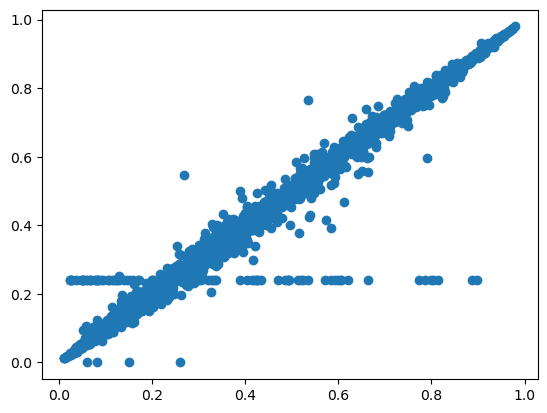

In [ ]:
plt.scatter(mp2_common_missmatch.MutPred2, mp2_common_missmatch.MutPred2_old)
print(f"length of common missmatch Variants: {len(mp2_common_missmatch.Variant.unique())}")
print(f"length of common missmatch Genes: {len(mp2_common_missmatch.unique())}")
plt.show()

In [33]:
import numpy as np
mp2_common_missmatch["reason_to_rescore"] = "do not agree with new"
mp2_missing["reason_to_rescore"] = "missing in new"
#print(mp2_new_non_target.head())
mp2_to_rescore = pd.concat([mp2_common_missmatch, mp2_missing])

print(f"length of to rescore: {len(mp2_to_rescore)}")
print(f"length of to rescore variants: {mp2_to_rescore.Variant.nunique()}")

mp2_non_target_rescore = mp2_new_non_target.copy().sample(n=1000)
mp2_non_target_rescore.rename(columns={"ENST": "ID", "aa_sub": "Substitution"}, inplace=True)
mp2_non_target_rescore = mp2_non_target_rescore[["Variant", "ID", "Substitution", "MutPred2"]]
mp2_non_target_rescore["MutPred2_old"] = np.nan
mp2_non_target_rescore["reason_to_rescore"] = "randomly selected non-target"
print(mp2_non_target_rescore.head())
print(f"length of non-target rescore: {len(mp2_non_target_rescore)}")


mp2_to_rescore2 = pd.concat([mp2_to_rescore, mp2_non_target_rescore])

mp2_to_rescore2 = mp2_to_rescore2.drop_duplicates(subset=["Variant", "ID", "Substitution"])

print(mp2_to_rescore2.head())
print(mp2_to_rescore2.reason_to_rescore.value_counts())
print(mp2_to_rescore2.MutPred2.value_counts())



length of to rescore: 42682
length of to rescore variants: 22718
               Variant                  ID Substitution  MutPred2  \
80663   1_45332242_C/T   ENST00000372104.5        G258E     0.932   
65631  1_237792289_C/A   ENST00000360064.7       S4566Y     0.896   
48469    9_2047285_C/T   ENST00000349721.7        P283S     0.152   
39043   17_7895028_G/A  ENST00000330494.11        V461I     0.205   
85092   1_15932809_A/G   ENST00000375759.7       Y2190C     0.092   

       MutPred2_old             reason_to_rescore  
80663           NaN  randomly selected non-target  
65631           NaN  randomly selected non-target  
48469           NaN  randomly selected non-target  
39043           NaN  randomly selected non-target  
85092           NaN  randomly selected non-target  
length of non-target rescore: 1000
                   ID Substitution  MutPred2          Variant  MutPred2_old  \
1   ENST00000372023.7        Y518C     0.084  20_47246490_T/C      0.084183   
73  ENST0000037

/var/folders/lj/6gfrhbf15_1_dhvth8xrbgjr0000gn/T/ipykernel_29195/3919694693.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mp2_common_missmatch["reason_to_rescore"] = "do not agree with new"


In [80]:
import numpy as np
np.log(1/9)/np.log(1.5834)
x = 1.8215
#x = 1.71715
print(np.power(x, 4))
# y = (x**10)/99
# print(y)
# y1 = (x**6)/9
# print(y1)
# alpha = 1- y/(1+y)
# print(alpha)
# alpha1 = 1- y1/(1+y1)
# print(alpha1)
y = (x**(1.5))
print(y)
alpha1 = 1-y/(1+y)
print(alpha1)


def lr_thresholds(alpha, x=1.71715):
    odds = alpha/(1-alpha)
    lr_p = 99.0/odds
    lr_lp = 9.0/odds
    # lr_p = np.log(99)/np.log(x) - np.log(odds)/np.log(x)
    # lr_lp = np.log(9)/np.log(x) - np.log(odds)/np.log(x)
    # lr_lb = 1/lr_lp
    # lr_b = 1/lr_p
    return lr_p, lr_lp


def points(lr, alpha, x=1.71715):
    odds = alpha/(1-alpha)
    points_adj = np.log(lr)/np.log(x) + np.log(odds)/np.log(x)
    points = np.log(lr)/np.log(x)
    return points, points_adj

alpha = alpha1
odds = alpha/(1-alpha)
# lr_p, lr_lp = 99.0, 9.0
lr_p, lr_lp = lr_thresholds(alpha, x)
lr_b, lr_lb = 1/lr_p, 1/lr_lp
print(lr_p, lr_lp, lr_lb, lr_b)
points_p, points_adj_p = points(lr_p, alpha,x)
points_lp, points_adj_lp = points(lr_lp, alpha,x)
points_b, points_adj_b = points(lr_b, alpha,x)
points_lb, points_adj_lb = points(lr_lb, alpha,x)
print(np.log(odds)/np.log(x))
print(points_p, points_lp, points_lb, points_b)
print(points_adj_p, points_adj_lp, points_adj_lb, points_adj_b)










11.00820990997506
2.4583502778031856
0.2891552097594985
243.37667750251538 22.12515250022867 0.04519742858222852 0.004108857143838956
-1.5
9.162871067225517 5.164115233332462 -5.164115233332462 -9.162871067225517
7.662871067225517 3.6641152333324616 -6.664115233332462 -10.662871067225517


In [81]:
print(np.log(99)/np.log(x))
print(np.log(9)/np.log(x))
print(np.log(1/99)/np.log(x))
print(np.log(1/9)/np.log(x))


7.662871067225517
3.6641152333324625
-7.662871067225517
-3.6641152333324625


In [35]:
mp2_to_rescore2.MutPred2.isna().sum()
mp2_to_rescore2.MutPred2_old.isna().sum()
mp2_to_rescore2.to_csv("mp2_to_rescore2.tsv", sep="\t", index=False)

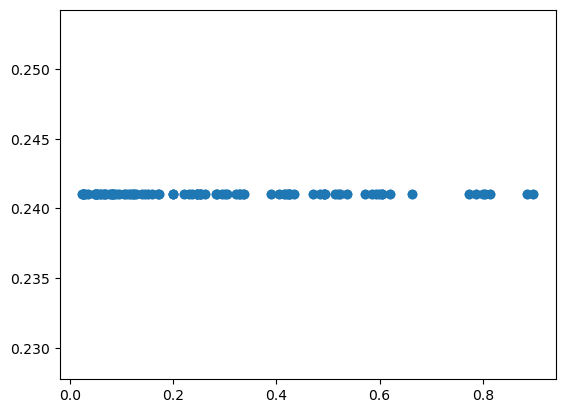

180
87


/var/folders/lj/6gfrhbf15_1_dhvth8xrbgjr0000gn/T/ipykernel_76852/377518337.py:11: DtypeWarning: Columns (18) have mixed types. Specify dtype option on import or set low_memory=False.
  clinVar_master = pd.read_csv(ClinVar_master_file, sep='\t')


['LAMA4' 'DNAAF3' 'CALR3' 'NEBL' 'TXNRD2' 'DNAAF5' 'HYDIN' 'RPGR' 'DNAI1'
 'PPP2R5D' 'PKD1' nan 'DNAAF1' 'NEXN' 'DNAH8' 'CCDC40']
number of variants in common: 3443
20130


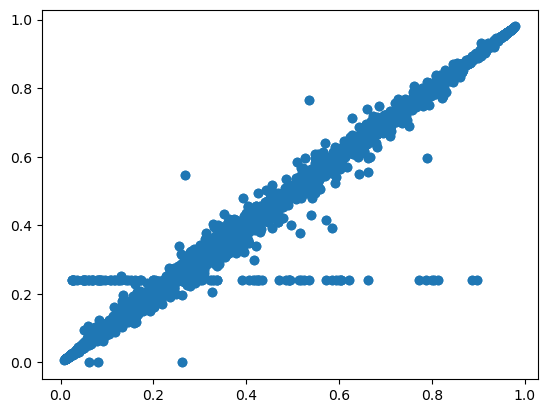

[nan 'DNAH8' 'DNAAF3' 'LAMA4' 'CALR3' 'NEXN' 'NEBL' 'PPP2R5D' 'TXNRD2'
 'DNAI1' 'DNAAF5' 'HYDIN' 'RPGR' 'PKD1' 'DNAAF1' 'CCDC40']
            ID
GeneSymbol    
CALR3        1
CCDC40       7
DNAAF1       4
DNAAF3       9
DNAAF5       3
DNAH8        4
DNAI1        4
HYDIN       10
LAMA4       12
NEBL         4
NEXN         4
PKD1         8
PPP2R5D      5
RPGR         4
TXNRD2      12
Number of variants_transcripts in common: 9255
Number of variants in common: 3443
                              Variant  Variant
GeneSymbol ID                                 
CALR3      ENST00000600762.1       44      9.0
CCDC40     ENST00000269318.9      145      6.0
           ENST00000374876.4      124      2.0
           ENST00000374877.7      250      6.0
           ENST00000571028.1       17      4.0
...                               ...      ...
TXNRD2     ENST00000475995.3       44      2.0
           ENST00000485358.5       68      5.0
           ENST00000491939.6       88      2.0
           ENST0

In [94]:
from ExTSP.config import ClinVar_master_file
high_error = mp2_common[(mp2_common.MutPred2 - mp2_common.MutPred2_old).abs()>0.1]
high_error = mp2_common[(mp2_common.MutPred2_old == 0.241) & (mp2_common.MutPred2 != 0.241)]
plt.scatter(high_error.MutPred2, high_error.MutPred2_old)
plt.show()
print(len(high_error))
print(high_error.Substitution.nunique())
high_error.head()


clinVar_master = pd.read_csv(ClinVar_master_file, sep='\t')
clinVar_master = clinVar_master[["Variant_ID", "GeneSymbol"]]
high_error = high_error.merge(clinVar_master, left_on="Variant", right_on="Variant_ID", how="left")
error_gene_list = high_error.GeneSymbol.unique()
error_variant_list = high_error.Variant.unique()
print(error_gene_list)

mp2_common2 = mp2_common.merge(clinVar_master, left_on="Variant", right_on="Variant_ID", how="left")
mp2_common2 = mp2_common2[mp2_common2.GeneSymbol.isin(error_gene_list)]
print(f"number of variants in common: {len(mp2_common2.Variant.unique())}")
plt.scatter(mp2_common2.MutPred2, mp2_common2.MutPred2_old)
print(len(mp2_common2))
plt.show()
print(mp2_common2.GeneSymbol.unique())
mp2_common_gt = mp2_common2[["GeneSymbol", "ID"]].drop_duplicates(subset=["GeneSymbol", "ID"])
mp2_common_gt = mp2_common_gt.groupby("GeneSymbol").count()
print(mp2_common_gt)

mp2_common2_gtv = mp2_common2[["Variant", "ID", "GeneSymbol"]].drop_duplicates(subset=["Variant", "ID", "GeneSymbol"])
print(f"Number of variants_transcripts in common: {len(mp2_common2_gtv)}")
mp2_common2_v = mp2_common2[["Variant"]].drop_duplicates(subset=["Variant"])
print(f"Number of variants in common: {len(mp2_common2_v)}")

mp2_common2_gtv_count = mp2_common2_gtv.groupby(["GeneSymbol", "ID"]).count()
mp2_common2_gtv_count.rename({"Variant": "all_variant_count"}, inplace=True)
mp2_common2_gtv_error_count = mp2_common2_gtv[mp2_common2_gtv.Variant.isin(error_variant_list)].groupby(["GeneSymbol", "ID"]).count()
mp2_common2_gtv_error_count.rename({"Variant": "variant_241_count"}, inplace=True)
variant_count = pd.concat([mp2_common2_gtv_count, mp2_common2_gtv_error_count], axis=1) 
variant_count.fillna(0, inplace=True)
print(variant_count)





In [36]:
variant_count.to_csv("variant_count.tsv", sep="\t")

In [74]:
mp2_old1 = pd.read_csv(file_old, sep="\t")
print(mp2_old1.columns)


Index(['external_gene_name', 'Feature', 'mutation', 'Substitution', 'mutpred',
       'transcript'],
      dtype='object')


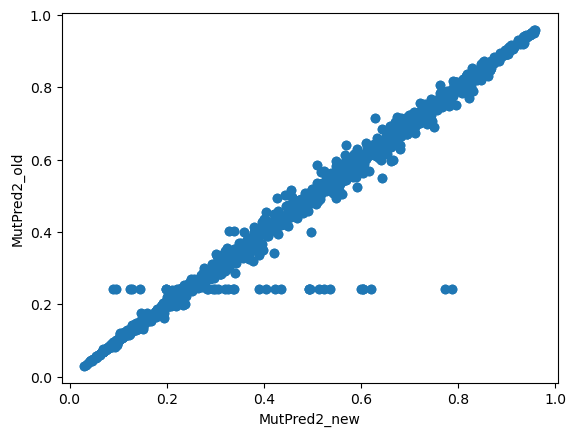

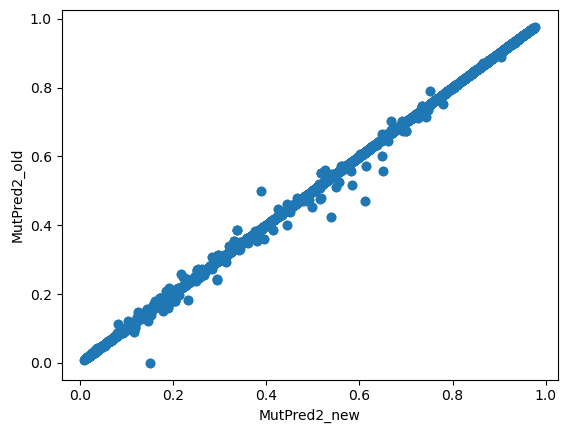

Index([], dtype='int64')
Index([], dtype='int64')
0


In [76]:
mp2_common1 = mp2_common.merge(clinVar_master, left_on="Variant", right_on="Variant_ID", how="left")
mp2_common_TTN = mp2_common1[mp2_common1.GeneSymbol == "TXNRD2"]
plt.scatter(mp2_common_TTN.MutPred2, mp2_common_TTN.MutPred2_old)
plt.xlabel("MutPred2_new")
plt.ylabel("MutPred2_old")
plt.show()

mp2_common_no_error_gene = mp2_common1[~mp2_common1.GeneSymbol.isin(error_gene_list)]
plt.scatter(mp2_common_no_error_gene.MutPred2, mp2_common_no_error_gene.MutPred2_old)
plt.xlabel("MutPred2_new")
plt.ylabel("MutPred2_old")
plt.show()



print(mp2_common2_TTN[mp2_common2_TTN.MutPred2_old == 0.241].index)
print(mp2_common2_TTN[mp2_common2_TTN.MutPred2==0.241].index)
print(mp2_common2_TTN.MutPred2.nunique())


In [85]:
print(len(mp2_new_plus))
mp2_new_plus1 = mp2_new_plus.merge(clinVar_master, left_on="Variant", right_on="Variant_ID", how="left")
print(len(mp2_new_plus1))
mp2_new_plus1 = mp2_new_plus1.drop_duplicates(subset=["Variant", "ID", "GeneSymbol"])
print(len(mp2_new_plus1))

print("mp2_new", len(mp2_new))
print("mp2_new", len(mp2_new[["Substitution", "ID"]].drop_duplicates(subset=["Substitution", "ID"])))

print("mp2_old", len(mp2_old))
print("mp2_old", len(mp2_old[["Substitution", "ID"]].drop_duplicates(subset=["Substitution", "ID"])))
print("mp2_old", len(mp2_old[["Variant", "ID"]].drop_duplicates(subset=["Variant", "ID"])))











259126
259190
82823
mp2_new 154114
mp2_new 154114
mp2_old 128611
mp2_old 62892
mp2_old 63191


16025
Index(['ID', 'Substitution', 'MutPred2'], dtype='object')
Index(['Variant', 'ID', 'Substitution', 'MutPred2_old'], dtype='object')
68552
34233
Variant                               C32Y
ID                       ENST00000482340.5
MutPred2_old_variance             0.000683
Name: 6003, dtype: object
0.4148410240026125


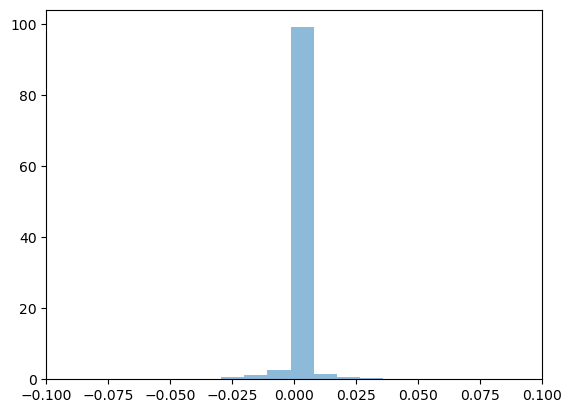

                Variant                  ID Substitution  MutPred2_old
502      6_43006611_G/A   ENST00000470467.5          R5Q         0.241
65432     11_687917_C/T   ENST00000527170.5          G8S         0.241
65433     11_687919_A/G   ENST00000527170.5          L7P         0.241
65434     11_687927_C/A   ENST00000527170.5          K4N         0.241
65823   6_157181053_G/A   ENST00000637904.1        D364N         0.241
...                 ...                 ...          ...           ...
605966  17_74301130_G/A  ENST00000311014.11        A317T         0.241
606799   6_38815504_A/G  ENST00000327475.11       I1124V         0.241
611220  10_27860663_C/T   ENST00000671855.1          D2N         0.241
627407  15_63057085_A/G   ENST00000705544.1         E10G         0.241
628898  1_237496578_T/A   ENST00000714021.1        L677M         0.241

[3468 rows x 4 columns]
                      ID          Variant  MutPred2_old
0     ENST00000070846.11  12_32796250_G/T      0.241000
1     ENST0

In [111]:
print(len(mp2_common.drop_duplicates(subset=["Substitution"])))
# mp2_new.rename(columns={"Substitution": "Variant"}, inplace=True)
# mp2_old.rename(columns={"Substitution": "Variant"}, inplace=True)
print(mp2_new.columns)
print(mp2_old.columns)
print(len(mp2_new.drop_duplicates(subset=["Substitution"])))
print(len(mp2_old.drop_duplicates(subset=["Substitution"])))

variance_df = mp2_old.groupby(["Substitution", "ID"]).agg({"MutPred2_old": "var"}).reset_index()
variance_df.columns = ["Variant", "ID", "MutPred2_old_variance"]
idx = variance_df["MutPred2_old_variance"].idxmax()
print(variance_df.loc[idx])

mp2_old[(mp2_old["Substitution"] == "C32Y") & (mp2_old["ID"] == "ENST00000482340.5")]


print(mp2_old.MutPred2_old.mean())


plt.hist(mp2_common.MutPred2_old-mp2_common.MutPred2, bins=100, density=True, alpha=0.5)
plt.xlim(-0.1, 0.1)
plt.show()

high_error = mp2_old[(mp2_old.MutPred2_old == 0.241)]
error_variant_list = high_error.Variant.unique()

print(high_error)
mp2_old2 = mp2_old.merge(high_error[["Variant", "ID"]], on=["ID", "Variant"], how="inner")
#mp2_old2_mean = mp2_old2.groupby(["ID", "Substitution"]).agg({"MutPred2_old": "mean"}).reset_index()
#for _, df in mp2_old2.groupby(["ID", "Variant"]):
#    print(df)

print(mp2_old2.groupby(["ID", "Variant"]).agg({"MutPred2_old": "mean"}).reset_index())




In [73]:
print("================")
print(f"mp2_common: {mp2_common.Variant.nunique()}")
print(f"mp2_new: {mp2_new.Variant.nunique()}")
print(f"mp2_old: {mp2_old.Variant.nunique()}")
print("mp2_old.columns", mp2_old.columns)

mp2_common: 11292
mp2_new: 68552
mp2_old: Variant    22831
Variant    34233
dtype: int64
mp2_old.columns Index(['Variant', 'ID', 'Variant', 'MutPred2_old'], dtype='object')


In [ ]:
old_file = OLD_DATA_DIR / "exTSP_scores/exTSP_score_beta_1_Cortical_Chau11.tsv"
old_df = pd.read_csv(old_file, sep="\t")
aaa = old_df[(old_df.Variant == "10_76910027_G/A") & (old_df.Transcript == "ENST00000372440")]
print(old_df.columns)
print(old_df.shape)
print(df.shape)
#print(old_df["Status"].value_counts())
print(old_df["ClinVar_annotation"].value_counts())



Index(['Gene', 'Transcript', 'Transcript_id', 'Variant', 'ClinVar_annotation',
       'Tissue', 'IsoPath', 'MutPred2', 'ptse', 'exTSP', 'MANE_Select',
       'MANE_Plus_Clinical', 'meanTPM'],
      dtype='object')
(26832, 13)
(16920, 23)
ClinVar_annotation
ASD        23472
Control     3360
Name: count, dtype: int64


length of new: 154114
length of to rescore file: 43682
length of rescored file: 43682
number of variants missing: 0


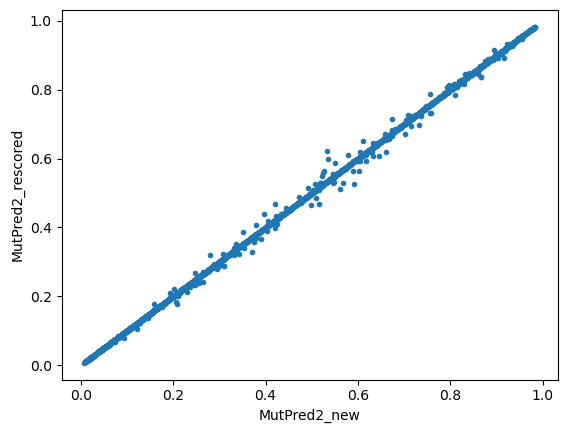

AttributeError: 'DataFrame' object has no attribute 'MutPred2_old'

In [ ]:
from re import M
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from ExTSP.config import FILTERED_DIR, MutPred2_filtered_file, ClinVar_master_file, MutPred2_processed_file
from ExTSP.tripletSets_exTSP import get_disease_variants, get_tripletSets_with_exTSP
from pathlib import Path
MP2_DIR = Path("MutPred2_scores")

file_new = MP2_DIR / "MutPred2_for_filtered_variants_SJ.tsv"
file_old = MP2_DIR / "mutpred_score_variant_transcript_Tulika.tsv"
file_new_plus = MP2_DIR / "MutPred2_for_filtered_variants_new_plus.tsv"
file_old_plus = MP2_DIR / "mutpred_for_filtered_variants_old_plus.tsv"
rescored_file = MP2_DIR / "mp2_rescore_combined_error.tsv"
to_rescore_file =  "mp2_to_rescore2.tsv"

mp2_new = pd.read_csv(file_new, sep="\t")
mp2_new = mp2_new.drop_duplicates(subset=["ID", "Substitution"])
print(f"length of new: {len(mp2_new)}")
mp2_old = pd.read_csv(file_old, sep="\t")
mp2_old.rename(columns={"Feature": "ID", "mutpred": "MutPred2_old", "mutation": "Variant"}, inplace=True)
mp2_old = mp2_old[["Variant", "ID", "Substitution",	"MutPred2_old"]]
mp2_old = mp2_old.drop_duplicates(subset=["Variant", "ID", "Substitution"])

mp2_to_rescore = pd.read_csv(to_rescore_file, sep="\t") 
print(f"length of to rescore file: {len(mp2_to_rescore)}")
mp2_rescored = pd.read_csv(rescored_file, sep="\t")
print(f"length of rescored file: {len(mp2_rescored)}")

variants_to_rescore = mp2_to_rescore.Variant.unique()
variants_rescored = mp2_rescored.Variant.unique()
variants_missing = np.setdiff1d(variants_to_rescore, variants_rescored)
print(f"number of variants missing: {len(variants_missing)}")

overlap_with_new = mp2_new.merge(mp2_rescored, on=["ID", "Substitution"], how="inner")

plt.plot(overlap_with_new.MutPred2_x, overlap_with_new.MutPred2_rescored, ".")
plt.xlabel("MutPred2_new")
plt.ylabel("MutPred2_rescored")
plt.show()

overlap_with_old = mp2_old.merge(mp2_rescored, on=["Variant", "ID", "Substitution"], how="inner")

plt.plot(overlap_with_old.MutPred2_old, overlap_with_old.MutPred2_rescored, ".")
plt.xlabel("MutPred2_old")
plt.ylabel("MutPred2_rescored")
plt.show()























In [ ]:
mp2_new = pd.read_csv(file_new, sep="\t")
mp2_rescored = pd.read_csv(rescored_file, sep="\t")
mp2_new["transcript"] = mp2_new["ID"].str.split(".").str[0]
#mp2_new.rename(columns={"ID": "ENST_SJ"}, inplace=True)
mp2_rescored["transcript"] = mp2_rescored["ID"].str.split(".").str[0]
#mp2_rescored.rename(columns={"ID": "ENST_rescored"}, inplace=True)
overlap_with_new = mp2_new.merge(mp2_rescored, on=["ID", "Substitution"], how="inner")
mp2_discrepancy = overlap_with_new[(overlap_with_new.MutPred2_x - overlap_with_new.MutPred2_rescored).abs() > 0.01]
mp2_discrepancy = mp2_discrepancy[["Variant", "ID", "Substitution", "MutPred2_x", "MutPred2_rescored"]]
mp2_discrepancy.rename(columns={"MutPred2_x": "MutPred2_SJ"}, inplace=True)
print(mp2_discrepancy)
mp2_discrepancy.to_csv("mp2_discrepancy.tsv", sep="\t", index=False)





              Variant                 ID Substitution  MutPred2_SJ  \
14    10_84212345_C/G  ENST00000372117.6        P313A        0.507   
2310  3_177047313_G/C  ENST00000631253.2        A284G        0.280   
2313  3_177053880_G/C  ENST00000631253.2         H33D        0.527   
2456  6_157181164_G/A  ENST00000635957.1        G219R        0.701   
2460  6_157207431_A/C  ENST00000635957.1       D1204A        0.545   
...               ...                ...          ...          ...   
3872  22_19941748_G/A  ENST00000400519.6         T19M        0.094   
3873  22_19941752_G/A  ENST00000400519.6         R18W        0.230   
3874  22_19941753_C/G  ENST00000400519.6         W17C        0.256   
3875  22_19941761_A/T  ENST00000400519.6         F15I        0.207   
3878  22_19941778_C/G  ENST00000400519.6          R9P        0.518   

      MutPred2_rescored  
14                0.525  
2310              0.319  
2313              0.564  
2456              0.673  
2460              0.528  
...

In [43]:
from ExTSP.config import BrainSpan_expression_file_all_regions
import pandas as pd
df_brainspan = pd.read_csv(BrainSpan_expression_file_all_regions, sep="\t")
print(df_brainspan.columns)
brainspan_transcripts = df_brainspan["transcript"].drop_duplicates()
brainspan_transcripts.to_csv("brainspan_transcripts.tsv", sep="\t", index=False)



Index(['transcript', 'external_gene_name', 'Regioncode', 'P2', 'P3', 'P4',
       'P5', 'P6', 'P7', 'P8', 'P9', 'P10', 'P11', 'P12', 'P13'],
      dtype='object')


In [ ]:
from ExTSP.isoformSelection.IsoformSelection_Variant import exTSP_selected_isoform, exTSP_selected_isoform_Tissue
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.metrics import auc
Tissue = "Heart_Left_Ventricle"
df_p_isoform = exTSP_selected_isoform(df_target_p)
df_b_isoform = exTSP_selected_isoform(df_target_b)
df_p_isoform_tissue = df_p_isoform[df_p_isoform.Tissue == Tissue]
df_b_isoform_tissue = df_b_isoform[df_b_isoform.Tissue == Tissue]
df_p_isoform_tissue = exTSP_selected_isoform_Tissue(df_target_p, Tissue)
df_b_isoform_tissue = exTSP_selected_isoform_Tissue(df_target_b, Tissue)


def auc(pos,neg):
    y_true = [1]*len(pos) + [0]*len(neg)
    y_pred = pos + neg
    return roc_auc_score(y_true, y_pred)

# Pathogenic versus benign in the picked tissue
auc_isoPath = auc(df_p_isoform_tissue.IsoPath.tolist(), df_b_isoform_tissue.IsoPath.tolist())
auc_exTSP = auc(df_p_isoform_tissue.exTSP.tolist(), df_b_isoform_tissue.exTSP.tolist())
print(f"Pathogenic versus benign in the picked tissue AUC of isoPath: {auc_isoPath}")
print(f"Pathogenic versus benign in the picked tissue AUC of exTSP: {auc_exTSP}")


# Pathogenic versus benign in the picked tissue
pos = df_p_isoform[df_p_isoform.Tissue == Tissue].IsoPath.to_list()
neg = df_b_isoform.IsoPath.to_list()













In [ ]:
from ExTSP.tripletSets_exTSP import get_tripletSets_with_exTSP_old2
from ExTSP.config import ExtractedVariants_file, ClinVar_master_file
import pandas as pd
diseases = {"CM": "cardiomyopathy", 
            "PCD": "primary ciliary dyskinesia",
            "PKD": "polycystic kidney disease", 
            "PH": "pulmonary hypertension", 
            #"ASD": "autism spectrum disorder",
            }

for d in diseases:
    df_target_all = get_tripletSets_with_exTSP_old2(d, type="all")
    df_target_all = df_target_all[["Variant"]].drop_duplicates()
    master_CV = pd.read_csv(ClinVar_master_file, sep='\t')
    df_target_all = df_target_all.merge(master_CV, left_on="Variant", right_on="Variant_ID", how="left")
    mask = df_target_all["PhenotypeList"].str.contains(diseases[d], case=False, na=False)
    print(len(df_target_all), mask.sum())
    # df_target_all = df_target_all[mask]
    df_target_all = df_target_all.drop(columns = ["Variant_ID"])
    print(df_target_all["Variant"].nunique())
    df_target_all = df_target_all[mask]
    print(df_target_all["Variant"].nunique())
    with pd.ExcelWriter(
    ExtractedVariants_file,
    mode="a",
    engine="openpyxl",
    if_sheet_exists="replace") as writer:
        df_target_all.to_excel(writer, sheet_name=f"{d}_old", index=False)
    

In [ ]:


y_true = [1]*len(pos_iso) + [0]*len(neg_iso)
y_pred = pos_iso + neg_iso

print(roc_auc_score(y_true, y_pred))


In [ ]:
from ExTSP.tripletSets_exTSP import get_tripletSets_with_exTSP
df_ASD_cases_brainspan = get_tripletSets_with_exTSP("ASD", "case", brainspan=True)

In [ ]:
df_target_all.columns


In [ ]:
import pandas as pd
from ExTSP.tripletSets_exTSP import get_tripletSets_with_exTSP
pcd =pd.read_csv("/Users/shajain/Library/CloudStorage/OneDrive-NortheasternUniversity/Box Sync/code/backup/ExTSP_old/data/isoformSelection/PCD_VITs.tsv", sep="\t")
pkd = pd.read_csv("/Users/shajain/Library/CloudStorage/OneDrive-NortheasternUniversity/Box Sync/code/backup/ExTSP_old/data/isoformSelection/KD_VITs.tsv", sep="\t")
pcd = get_tripletSets_with_exTSP("PCD", "all", brainspan=False)
pkd = get_tripletSets_with_exTSP("PKD", "all", brainspan=False)
ph = get_tripletSets_with_exTSP("PH", "all", brainspan=False)

In [ ]:
from ExTSP.commonFunctions import clinSig_bool
pcd = pcd.drop_duplicates(subset=["Variant"])
pkd = pkd.drop_duplicates(subset=["Variant"])
ph = ph.drop_duplicates(subset=["Variant"])
pcd_p, pcd_plp, pcd_vus, pcd_blb, pcd_b = clinSig_bool(pcd.ClinVar_annotation)
pkd_p, pkd_plp, pkd_vus, pkd_blb, pkd_b = clinSig_bool(pkd.ClinVar_annotation)
ph_p, ph_plp, ph_vus, ph_blb, ph_b = clinSig_bool(ph.ClinVar_annotation)

print("===========PCD===========")
print(f"Variants: P: {pcd_p.sum()}, PLP: {pcd_plp.sum()}, VUS: {pcd_vus.sum()}, BLB: {pcd_blb.sum()}, B: {pcd_b.sum()}")
print(f'Genes: P: {pcd[pcd_p]["Gene"].nunique()}, PLP: {pcd[pcd_plp]["Gene"].nunique()}, VUS: {pcd[pcd_vus]["Gene"].nunique()}, BLB: {pcd[pcd_blb]["Gene"].nunique()}, B: {pcd[pcd_b]["Gene"].nunique()}')
print("===========PKD===========")
print(f"Variants: P: {pkd_p.sum()}, PLP: {pkd_plp.sum()}, VUS: {pkd_vus.sum()}, BLB: {pkd_blb.sum()}, B: {pkd_b.sum()}")
print(f'Genes: P: {pkd[pkd_p]["Gene"].nunique()}, PLP: {pkd[pkd_plp]["Gene"].nunique()}, VUS: {pkd[pkd_vus]["Gene"].nunique()}, BLB: {pkd[pkd_blb]["Gene"].nunique()}, B: {pkd[pkd_b]["Gene"].nunique()}')
print("===========PH===========")
print(f"Variants: P: {ph_p.sum()}, PLP: {ph_plp.sum()}, VUS: {ph_vus.sum()}, BLB: {ph_blb.sum()}, B: {ph_b.sum()}")
print(f'Genes: P: {ph[ph_p]["Gene"].nunique()}, PLP: {ph[ph_plp]["Gene"].nunique()}, VUS: {ph[ph_vus]["Gene"].nunique()}, BLB: {ph[ph_blb]["Gene"].nunique()}, B: {ph[ph_b]["Gene"].nunique()}')





In [ ]:
import pandas as pd
from ExTSP.config import OLD_DATA_DIR
disease = "PCD"
df_extsp2 = pd.read_csv(OLD_DATA_DIR/ f"classification/exTSP_file_expression_ensemble_annotation_{disease}.tsv", sep='\t')
df_extsp2.columns

In [ ]:
from ExTSP.classification.auc_bootstrap import bootstrap_auc_for_disease
from ExTSP.config import Diseases
for disease in ["PCD"]:
    print(f"================{disease}=================")
    for i in range(4,6):
        if disease == "ASD" and i > 3:
            continue
        print(f"Setting {i}")
        result1, summary1 = bootstrap_auc_for_disease(disease, i, n_bootstrap=10, prop_gene_draws=1.0, use_old_data=False)
        print(f"\tStandard means: IsoPath: {summary1['mean_auc_isopath']:.3f}, exTSP: {summary1['mean_auc_extsp']:.3f}")
        print(f"\tStandard medians: IsoPath: {summary1['median_auc_isopath']:.3f}, exTSP: {summary1['median_auc_extsp']:.3f}")
        if i != 3:
            result2, summary2 = bootstrap_auc_for_disease(disease, i, balanced_negative=True, n_bootstrap=10, prop_gene_draws=1.0, use_old_data=False)
            print(f"\tBalanced means: IsoPath: {summary2['mean_auc_isopath']:.3f}, exTSP: {summary2['mean_auc_extsp']:.3f}")
            print(f"\tBalanced medians: IsoPath: {summary2['median_auc_isopath']:.3f}, exTSP: {summary2['median_auc_extsp']:.3f}")

In [ ]:
from ExTSP.config import ExtractedVariants_file
import pandas as pd
df_vars = pd.DataFrame()
diseases = ["CM", "PCD", "PH", "PKD", "ASD", "nonTarget"]

for disease in diseases:
    df_disease = get_disease_variants(disease)
    #print(df_disease.columns)
    print(f"length of {disease}: {len(df_disease)}")
    df_disease['Disease'] = disease
    if disease == "nonTarget":
        df_disease["is_target"] = False
    else:
        df_disease["is_target"] = True
    # df_disease_dedup = df_disease.drop_duplicates(subset=["Variant", "GeneSymbol"])
    # print(f"number of unique variants: {len(df_disease_dedup)}")
    df_vars = pd.concat([df_vars, df_disease])  


    len(df_vars)

    



# All_Vars = pd.concat([SDVs_all, nonTarget_df[["GeneSymbol", "Variant", "Target"]]], ignore_index=True)
# #assert All_Vars[["Variant", "GeneSymbol"]].duplicated().sum() == 0, "Duplicate variants found in All_Vars"
# with pd.ExcelWriter(extractedVariantsFile, mode="a", engine="openpyxl", if_sheet_exists="replace") as writer:
# All_Vars.to_excel(writer, index=False, sheet_name="Variants_all")



length of CM: 25418
length of PCD: 6946
length of PH: 342
length of PKD: 1724
length of ASD: 1436
length of nonTarget: 20000


KeyError: "Column(s) ['disease'] do not exist"

In [ ]:
df_vars = df_vars[["Variant", "GeneSymbol", "Disease", "is_target"]]
df_vars1 = df_vars.groupby(["Variant", "GeneSymbol"]).agg({"is_target": lambda x: x.any(), 'Disease': lambda x: ', '.join(x)}).reset_index()

df_vars.head()

,Variant,GeneSymbol,is_target,Disease
0,10_100209695_C/T,CHUK,False,nonTarget
1,10_100293374_C/A,PKD2L1,False,nonTarget
2,10_100297026_C/T,PKD2L1,False,nonTarget
3,10_100529393_C/T,NDUFB8,False,nonTarget
4,10_100529817_T/C,NDUFB8,False,nonTarget


In [62]:
diseases = [[dd.strip() for dd in d.split(",")] for d in df_vars.Disease]
ix_multi_disease = [len(d) > 2 for d in diseases]

print(df_vars.loc[ix_multi_disease, "Disease"]) 


21346    CM, PCD, nonTarget
39676    ASD, ASD, ASD, ASD
Name: Disease, dtype: object


In [76]:
df_nt = get_disease_variants("nonTarget_new")
df_nt['is_target'] = False
df_nt['Disease'] = ''
print(len(df_nt))
print(df_nt.drop_duplicates(subset=["Variant", "GeneSymbol"]).shape)
diseases = ["CM_new", "PCD_new", "PH_new", "PKD_new", "ASD"]
df_vars = pd.DataFrame()
for disease in diseases:
    df_disease = get_disease_variants(disease)
    #print(df_disease.columns)
    print(f"length of {disease}: {len(df_disease)}")
    df_disease['Disease'] = disease
    if disease == "nonTarget":
        df_disease["is_target"] = False
    else:
        df_disease["is_target"] = True
    # df_disease_dedup = df_disease.drop_duplicates(subset=["Variant", "GeneSymbol"])
    # print(f"number of unique variants: {len(df_disease_dedup)}")
    df_vars = pd.concat([df_vars, df_disease])  


  







20000
(20000, 43)
length of CM_new: 25625
length of PCD_new: 8459
length of PH_new: 325
length of PKD_new: 2084
length of ASD: 1436


In [78]:
df_vars2 = pd.concat([df_nt, df_vars])
df_vars2 = df_vars2[["Variant", "GeneSymbol", "Disease", "is_target"]]
print(df_vars2)
print(df_nt.Disease)
df_vars3 = df_vars2.groupby(["Variant", "GeneSymbol"]).agg({"is_target": lambda x: x.any(), 'Disease': lambda x: ', '.join(x)}).reset_index()

diseases = [[dd.strip() for dd in d.split(",")] for d in df_vars.Disease]
ix_multi_disease = [len(d) > 1 for d in diseases]

print(df_vars.loc[ix_multi_disease, "Disease"]) 


               Variant GeneSymbol Disease  is_target
0       6_49440295_C/T       MMUT              False
1      6_112054360_G/T       CCN6              False
2      12_49026691_C/A      KMT2D              False
3      14_21320019_C/T    RPGRIP1              False
4     12_120997633_T/G      HNF1A              False
...                ...        ...     ...        ...
1431    9_93653223_C/T       PHF2     ASD       True
1432    9_93675706_C/T       PHF2     ASD       True
1433    9_93676510_T/C       PHF2     ASD       True
1434    9_96420400_C/G       PHF2     ASD       True
1435    9_96437988_C/T       PHF2     ASD       True

[57929 rows x 4 columns]
0         
1         
2         
3         
4         
        ..
19995     
19996     
19997     
19998     
19999     
Name: Disease, Length: 20000, dtype: object
Series([], Name: Disease, dtype: object)


In [ ]:
from ExTSP.tripletSets_exTSP import get_disease_variants
import pandas as pd
df_nt = get_disease_variants("nonTarget_new")
print(len(df_nt))
print(df_nt.drop_duplicates(subset=["Variant", "GeneSymbol"]).shape)
diseases = ["CM", "PCD", "PH", "PKD", "ASD"]
for disease in diseases:
    df_disease = get_disease_variants(disease)
    #print(df_disease.columns)
    print(f"length of {disease}: {len(df_disease)}")
    # df_disease_dedup = df_disease.drop_duplicates(subset=["Variant", "GeneSymbol"])
    # print(f"number of unique variants: {len(df_disease_dedup)}")
    df_vars = pd.concat([df_vars, df_disease])  

disease_vars = df_vars.Variant.unique()

df_nt = df_nt[~df_nt.Variant.isin(disease_vars)]
len(df_nt)

BadZipFile: File name in directory '[Content_Types].xml' and header b'docProps/app.xml' differ.

In [83]:
import pandas as pd
from ExTSP.config import ExtractedVariants_file
with pd.ExcelWriter(ExtractedVariants_file, mode="a", engine="openpyxl", if_sheet_exists="replace") as writer:
    df_nt.to_excel(writer, index=False, sheet_name="nonTarget")

BadZipFile: File name in directory '[Content_Types].xml' and header b'docProps/app.xml' differ.

In [4]:
from ExTSP.tripletSets_exTSP import get_variant_sets, get_disease_variants
from ExTSP.config import ExtractedVariants_file, ClinVar_master_file, FILTERED_DIR
import pandas as pd
diseases = ["CM", "PCD", "PH", "PKD", "ASD"]
CV_df = pd.read_csv(ClinVar_master_file, sep='\t')
df_all = pd.DataFrame()
for disease in diseases:
    df_disease = get_variant_sets(disease)
    df_disease.rename(columns={"Variant_ID": "Variant"}, inplace=True)
    if disease != "ASD":
        df_disease = df_disease[["Variant", "GeneSymbol"]].drop_duplicates()
        df_disease = df_disease.merge(CV_df, left_on=["Variant", "GeneSymbol"], right_on=["Variant_ID", "GeneSymbol"], how="left")
        df_disease.drop(columns=["Variant_ID"], inplace=True)
    
    print(f"length of {disease}: {len(df_disease)}")
    #with pd.ExcelWriter(ExtractedVariants_file, mode="a", engine="openpyxl", if_sheet_exists="replace") as writer:
    with pd.ExcelWriter(ExtractedVariants_file, mode="a", engine="openpyxl", if_sheet_exists="replace") as writer:
        df_disease.to_excel(writer, index=False, sheet_name=disease)
    df_disease["Disease"] = disease
    df_disease["is_target"] = True
    df_all = pd.concat([df_all, df_disease[["Variant", "GeneSymbol", "Disease", "is_target"]]])

disease_vars = df_all.Variant.unique()
nonTarget_file = FILTERED_DIR / "extractedVariants_copy.xlsx"
df_nt = get_disease_variants("nonTarget", file=nonTarget_file)
df_nt["Disease"] = ""
df_nt["is_target"] = False
print(f"length of nonTarget before removing disease variants: {len(df_nt)}")
df_nt = df_nt[~df_nt.Variant.isin(disease_vars)]
print(f"length of nonTarget after removing disease variants: {len(df_nt)}")
with pd.ExcelWriter(ExtractedVariants_file, mode="a", engine="openpyxl", if_sheet_exists="replace") as writer:
    df_nt.to_excel(writer, index=False, sheet_name="nonTarget")

df_all = pd.concat([df_all, df_nt[["Variant", "GeneSymbol", "Disease", "is_target"]]])
with pd.ExcelWriter(ExtractedVariants_file, mode="a", engine="openpyxl", if_sheet_exists="replace") as writer:
    df_all.to_excel(writer, index=False, sheet_name="all_variants")
    










/var/folders/lj/6gfrhbf15_1_dhvth8xrbgjr0000gn/T/ipykernel_14360/3086435227.py:5: DtypeWarning: Columns (18) have mixed types. Specify dtype option on import or set low_memory=False.
  CV_df = pd.read_csv(ClinVar_master_file, sep='\t')


length of CM: 27559
length of PCD: 8843
length of PH: 414
length of PKD: 2266
length of ASD: 1429
length of nonTarget before removing disease variants: 20000
length of nonTarget after removing disease variants: 19722


In [10]:
import pandas as pd
from ExTSP.config import FILTERED_DIR, OLD_DATA_DIR
all_vars = pd.read_csv(FILTERED_DIR / "all_variants.txt", sep="\t")
all_vars = all_vars.Variant.unique()
TARGET_DIR = OLD_DATA_DIR / "targetVariants"
diseases = ["CM", "PCD", "PH", "PKD", "ASD"]
for disease in diseases:
    df_disease = pd.read_csv(TARGET_DIR / f"High_confident_SNP_mutations_{disease}.tsv", sep="\t")
    disease_vars = df_disease[["Variant_ID"]].drop_duplicates()
    print((disease_vars.Variant_ID.isin(all_vars)).sum()) 



new_vars = pd.read_excel(FILTERED_DIR / "extractedVariants_copy.xlsx", sheet_name="nonTarget")
print((new_vars.Variant.isin(all_vars)).sum())













27540
8828
414
2263
1425
20000


In [17]:
all_vars = pd.read_csv(FILTERED_DIR / "all_variants.txt", sep="\t")
asd_vars = all_vars[all_vars.Disease=="ASD"]
print(len(asd_vars))


df_asd = pd.read_csv(TARGET_DIR / f"High_confident_SNP_mutations_ASD.tsv", sep="\t")
print(len(df_asd))

print(df_asd.Variant_ID.isin(asd_vars.Variant).sum())
print(asd_vars.Variant.isin(df_asd.Variant_ID).sum())




print(df_asd)
print(asd_vars)

asd_vars.to_csv(FILTERED_DIR / "asd_vars.txt", sep="\t", index=False)




1429
1429
1429
1429
            Variant_ID Variant_ID_hg38_lifted  chr  hg38_start   hg38_end REF  \
0     10_112951122_A/G       10:112951122:A:G   10   112951122  112951122   A   
1     10_113040024_G/C       10:113040024:G:C   10   113040024  113040024   G   
2     10_113089541_G/A       10:113089541:G:A   10   113089541  113089541   G   
3     10_113126927_C/T       10:113126927:C:T   10   113126927  113126927   C   
4     10_113141317_G/A       10:113141317:G:A   10   113141317  113141317   G   
...                ...                    ...  ...         ...        ...  ..   
1424    9_93653223_C/T         9:93653223:C:T    9    93653223   93653223   C   
1425    9_93675706_C/T         9:93675706:C:T    9    93675706   93675706   C   
1426    9_93676510_T/C         9:93676510:T:C    9    93676510   93676510   T   
1427    9_96420400_C/G         9:96420400:C:G    9    96420400   96420400   C   
1428    9_96437988_C/T         9:96437988:C:T    9    96437988   96437988   C   

     AL

In [24]:
from ExTSP.config import BRAINSPAN_DIR, BrainSpan_expression_file_all_regions
import pandas as pd
df_brainspan = pd.read_csv(BrainSpan_expression_file_all_regions, sep="\t")
df_brainspan = df_brainspan["transcript"].drop_duplicates()
df_brainspan.to_csv('brainspan_transcripts.tsv', sep="\t", index=False)





In [2]:
import numpy as np
np.log(111.0)/np.log(1.82116)

np.float64(7.85610863342765)